In [1]:
import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%load_ext autoreload
%autoreload 2

In [74]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [3.2489276324892766, 2.0079477038671003]


### with old dataset and all 16bit

In [88]:
api = wandb.Api()
results = []
# t_run = tqdm(api.sweep("ddold/subspace_bezier_length_dnn/taa7hglw").runs)
for s in ["yqlk3puv",]:
# for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    NumSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

yqlk3puv:   0%|          | 0/96 [00:00<?, ?it/s, major-sweep-90]    

yqlk3puv: 100%|██████████| 96/96 [00:00<00:00, 347.09it/s, glowing-sweep-1]   


,Id,NumSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,kz2axb5d,2,16,0.01,boolq,19.841238,0.889375,0.886813,0.289062,0.292969
1,5yzv7v76,2,8,0.01,boolq,19.822430,0.885937,0.883388,0.298828,0.300781
2,bmfwlzr3,2,4,0.01,boolq,19.825733,0.882500,0.880325,0.289062,0.292969
3,kddkh5rk,2,1,0.01,boolq,19.841034,0.884375,0.881288,0.292969,0.294922
4,ogy1fd4y,0,16,0.00,boolq,0.000000,0.888438,0.888437,0.289062,0.289062
...,...,...,...,...,...,...,...,...,...,...
91,40ndqj5o,0,1,0.01,obqa,0.000000,0.894000,0.894000,0.392578,0.392578
92,uabqy14s,0,16,0.01,winogrande_m,0.000000,0.776667,0.776667,0.828125,0.828125
93,bdpj3rs1,0,8,0.01,winogrande_m,0.000000,0.759167,0.759167,0.878906,0.878906
94,lrs0s3bk,0,4,0.01,winogrande_m,0.000000,0.770000,0.770000,0.820312,0.820312


In [89]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,NumSpace,Seed,WeightDecay,Dataset,,,,,


In [90]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")

Unique configuartions: 
NumSpace [2 0]
Seed [16  8  4  1]
WeightDecay [0.01 0.  ]
Dataset ['boolq' 'ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m']

Experiment differs in ['NumSpace', 'WeightDecay', 'Dataset'] configs


In [91]:
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [92]:
# Reference accuracy values from table
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}


#### acc

/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From 

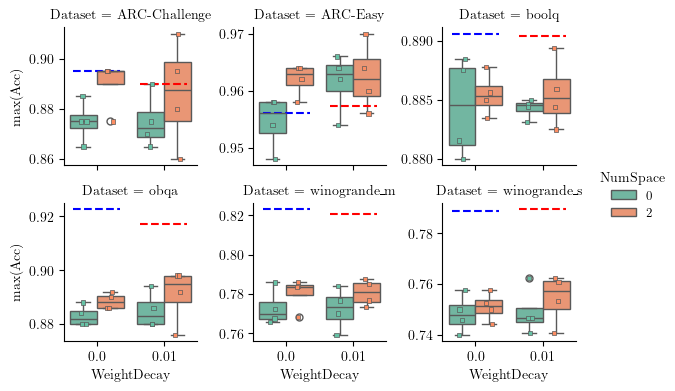

In [93]:

g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='NumSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='NumSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )

g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

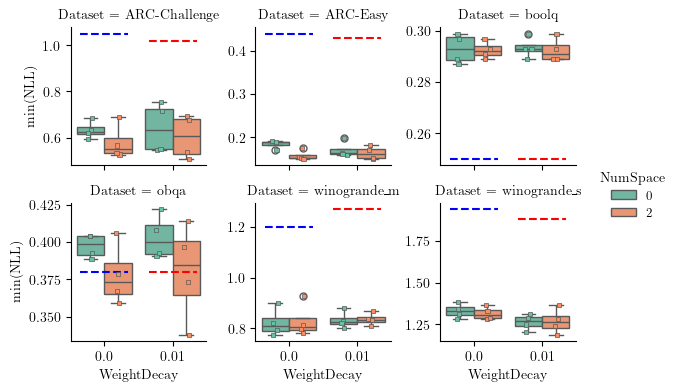

In [94]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='NumSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='NumSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### with lora for lmhead and 32bit lora and new dataset

In [100]:
api = wandb.Api()
results = []
# t_run = tqdm(api.sweep("ddold/subspace_bezier_length_dnn/taa7hglw").runs)
for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    NumSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

vj9z5em9:   0%|          | 0/96 [00:00<?, ?it/s, graceful-sweep-77]

vj9z5em9: 100%|██████████| 96/96 [00:00<00:00, 417.28it/s, legendary-sweep-1]   


,Id,NumSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,q5r8g6l7,2,16,0.00,ARC-Easy,2389.498291,0.300000,0.264160,1.382812,1.390625
1,wqlzfn1d,2,8,0.00,ARC-Easy,2389.168701,0.296000,0.248720,1.382812,1.390625
2,0u4s48wh,2,4,0.00,ARC-Easy,2389.728516,0.312000,0.278400,1.375000,1.382812
3,zxg854iy,2,1,0.00,ARC-Easy,2390.661621,0.300000,0.258560,1.382812,1.390625
4,26e8sa0j,2,16,0.00,ARC-Challenge,2389.499023,0.305000,0.267600,1.382812,1.390625
...,...,...,...,...,...,...,...,...,...,...
91,adqz0mbr,0,1,0.01,winogrande_s,0.000000,0.730833,0.730833,2.093750,2.093750
92,7bvhrshl,0,16,0.01,winogrande_m,0.000000,0.770833,0.770833,1.304688,1.304688
93,otbcme7g,0,8,0.01,winogrande_m,0.000000,0.778333,0.778333,1.187500,1.187500
94,eemezr9i,0,4,0.01,winogrande_m,0.000000,0.778333,0.778333,1.125000,1.125000


In [101]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,NumSpace,Seed,WeightDecay,Dataset,,,,,


In [102]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
NumSpace [2 0]
Seed [16  8  4  1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['NumSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_385792/2274057907.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/2274057907.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/2274057907.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/2274057907.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/2274057907.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/2274057907.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

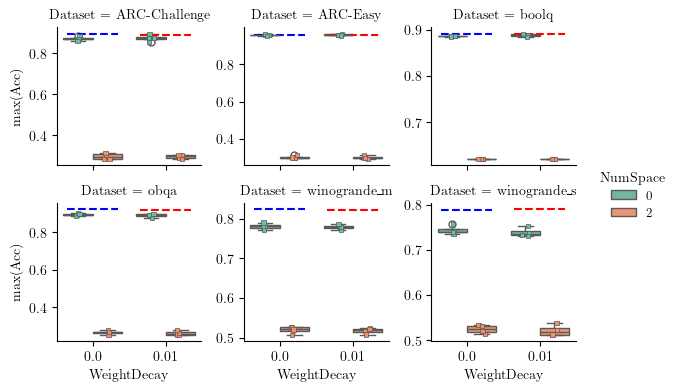

In [103]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['NumSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='NumSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='NumSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

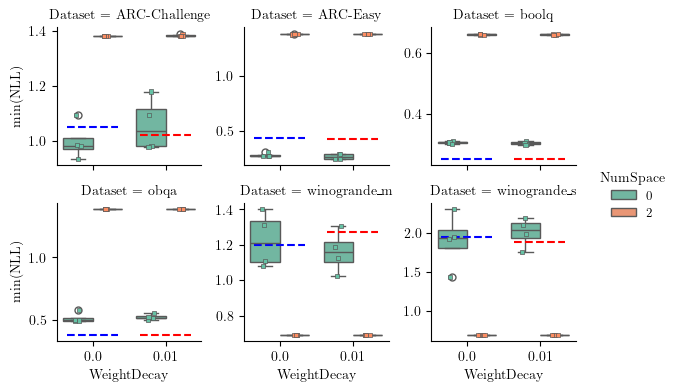

In [104]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='NumSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='NumSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()